# ĐỒ ÁN: PHÂN TÍCH, ĐÁNH GIÁ VÀ MÔ PHỎNG ĐẢO NHIỆT ĐÔ THỊ (UHI) TP. HỒ CHÍ MINH GIAI ĐOẠN 2020–2026

**Môn học:** Tin học Tài nguyên và Môi trường
**Công cụ:** Python + Google Earth Engine (GEE) + geemap

---

## Mục lục
1. Thiết lập môi trường & xác thực Google Earth Engine
2. Xác định vùng nghiên cứu (AOI) — TP. Hồ Chí Minh
3. Hàm xử lý ảnh Landsat: che mây, tính LST, NDVI, NDBI, NDWI, UTFVI
4. Xây dựng chuỗi ảnh composite theo năm (2020–2026)
5. Trích xuất thống kê định lượng (LST, NDVI trung bình mỗi năm)
6. Trực quan hoá xu hướng nhiệt độ bề mặt theo thời gian
7. Bản đồ LST tương tác từng năm (geemap)
8. Phân vùng cường độ đảo nhiệt bằng chỉ số UTFVI
9. Phân tích tương quan LST ~ NDVI ~ NDBI
10. Xuất dữ liệu raster ra Google Drive (phục vụ GIS/QGIS)
11. **MÔ PHỎNG**: Dự báo xu hướng LST 2027–2030 (Regression)
12. **MÔ PHỎNG**: Dự báo mở rộng đô thị bằng CA–Markov đơn giản
13. Tổng hợp kết quả & gợi ý viết báo cáo

> **Lưu ý:** Notebook này chạy trên **Google Colab**. Khi chạy lần đầu, Colab sẽ yêu cầu đăng nhập tài khoản Google để xác thực Earth Engine.


## 1. Thiết lập môi trường & xác thực Google Earth Engine

In [1]:
# Cài đặt các thư viện cần thiết (chạy 1 lần, nếu dùng Colab thường đã có sẵn earthengine-api)
!pip install -q geemap earthengine-api rasterio geopandas scikit-learn rioxarray



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\Legion\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime

# Xác thực & khởi tạo Earth Engine
# Lần đầu chạy sẽ mở cửa sổ đăng nhập Google -> dán mã xác thực
try:
    ee.Initialize(project='wired-tea-470916-u2')   
except Exception:
    ee.Authenticate()
    ee.Initialize(project='wired-tea-470916-u2')

print("Kết nối Google Earth Engine thành công!")


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Kết nối Google Earth Engine thành công!


## 2. Xác định vùng nghiên cứu (AOI) — TP. Hồ Chí Minh

Dùng ranh giới hành chính cấp tỉnh từ FAO GAUL (hoặc em có thể thay bằng file shapefile ranh giới TPHCM tự có, upload lên rồi đọc bằng `geemap.shp_to_ee()`).


In [3]:
# ==== BƯỚC 2 (PHIÊN BẢN ỔN ĐỊNH): Gộp 3 tỉnh cũ bằng FAO GAUL (có sẵn trong GEE) ====
# Không cần osmnx/geopandas nữa - dùng thẳng dữ liệu ranh giới có sẵn trên GEE,
# ổn định hơn nhiều so với OSM (vốn chưa cập nhật đầy đủ ranh giới sáp nhập).

import geemap
import ee

gaul = ee.FeatureCollection("FAO/GAUL/2015/level1")

# Lọc đúng 3 tỉnh/thành cũ hợp thành TP.HCM mới
ten_3_tinh = ["Ho Chi Minh City", "Binh Duong", "Ba Ria-Vung Tau"]
aoi = gaul.filter(ee.Filter.inList("ADM1_NAME", ten_3_tinh))

# In ra để kiểm tra có đủ 3 feature không (đúng phải ra 3)
so_luong = aoi.size().getInfo()
print("Số vùng lọc được (phải là 3):", so_luong)
print("Tên các vùng lấy được:", aoi.aggregate_array("ADM1_NAME").getInfo())

# .geometry() trên FeatureCollection tự động gộp (union) tất cả feature thành 1 khối
aoi_geom = aoi.geometry()

# Kiểm tra bằng bản đồ
Map = geemap.Map(center=[10.9, 107.0], zoom=8)
Map.addLayer(aoi, {"color": "red"}, "TP.HCM mới (gộp 3 tỉnh qua FAO GAUL)")
Map.centerObject(aoi, 8)
Map

c:\Users\Legion\anaconda3\envs\seocntt3\Lib\site-packages\ee\deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level1! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level1

  warnings.warn(warning, category=DeprecationWarning)


Số vùng lọc được (phải là 3): 3
Tên các vùng lấy được: ['Ba Ria-Vung Tau', 'Binh Duong', 'Ho Chi Minh City']


Map(center=[10.86837060102549, 106.84623864149141], controls=(WidgetControl(options=['position', 'transparent_…

## 3. Hàm xử lý ảnh Landsat 8/9 Collection 2 Level 2

- **Che mây** dùng band `QA_PIXEL`
- **LST**: Landsat Collection 2 Level 2 đã cung cấp sẵn band `ST_B10` (Surface Temperature đã hiệu chỉnh khí quyển & phát xạ) → chỉ cần áp hệ số scale/offset, không cần tự làm mono-window từ đầu.
- **NDVI** (thực vật), **NDBI** (xây dựng), **NDWI** (nước) tính từ band phản xạ bề mặt (Surface Reflectance, `SR_B*`).


In [4]:
# Ngưỡng độ bất định nhiệt độ bề mặt (Kelvin) chấp nhận được, theo band ST_QA của USGS.
ST_QA_MAX_K = 5.0

def mask_l8sr(image):
    """Che pixel kém chất lượng dùng QA_PIXEL + ST_QA (Collection 2 Level 2).

    Bản cũ chỉ che bit 3 (mây) và bit 4 (bóng mây) -> còn lọt viền mây, mây ti và
    pixel có sai số nhiệt cao, sinh ra vài điểm LST bất thường (vd. 67°C trên vườn cây).
    Bản này che thêm:
      bit 0 = fill, bit 1 = viền mây (dilated cloud), bit 2 = mây ti (cirrus),
      và pixel có độ bất định nhiệt độ bề mặt ST_QA > ST_QA_MAX_K (Kelvin).
    """
    qa = image.select('QA_PIXEL')
    bad_bits = (1 << 0) | (1 << 1) | (1 << 2) | (1 << 3) | (1 << 4)
    qa_ok = qa.bitwiseAnd(bad_bits).eq(0)
    st_uncert_k = image.select('ST_QA').multiply(0.01)   # ST_QA: hệ số scale 0.01, đơn vị K
    st_ok = st_uncert_k.lte(ST_QA_MAX_K)
    return image.updateMask(qa_ok.And(st_ok))


def scale_bands(image):
    """Áp hệ số scale/offset chuẩn của USGS cho SR và ST."""
    optical = image.select('SR_B.').multiply(0.0000275).add(-0.2)
    thermal = image.select('ST_B10').multiply(0.00341802).add(149.0)
    return image.addBands(optical, None, True).addBands(thermal, None, True)


def add_lst_celsius(image):
    lst = image.select('ST_B10').subtract(273.15).rename('LST')
    return image.addBands(lst)


def add_indices(image):
    ndvi = image.normalizedDifference(['SR_B5', 'SR_B4']).rename('NDVI')
    ndbi = image.normalizedDifference(['SR_B6', 'SR_B5']).rename('NDBI')
    ndwi = image.normalizedDifference(['SR_B3', 'SR_B5']).rename('NDWI')
    return image.addBands([ndvi, ndbi, ndwi])


def process_image(image):
    image = mask_l8sr(image)
    image = scale_bands(image)
    image = add_lst_celsius(image)
    image = add_indices(image)
    return image

print("Đã định nghĩa xong các hàm xử lý ảnh.")

Đã định nghĩa xong các hàm xử lý ảnh.


## 4. Xây dựng ảnh composite theo năm (mùa khô, 2020–2026)

TP.HCM mùa mưa (~tháng 5–11) có mây rất nhiều, ảnh quang học/nhiệt dễ bị che khuất. Để đảm bảo **so sánh được giữa các năm**, ta lấy composite (trung vị - median) ảnh trong **mùa khô** (tháng 1–3) mỗi năm.

Landsat 9 hoạt động từ tháng 10/2021, nên với 2020–2021 ta chỉ dùng Landsat 8; từ 2022 trở đi kết hợp cả Landsat 8 và 9 để tăng số lượng ảnh sạch mây.


In [5]:
def get_yearly_composite(year, aoi_geom, start_md='01-01', end_md='03-31'):
    start = f'{year}-{start_md}'
    end = f'{year}-{end_md}'

    l8 = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
          .filterBounds(aoi_geom)
          .filterDate(start, end)
          .filter(ee.Filter.lt('CLOUD_COVER', 20))
          .map(process_image))

    l9 = (ee.ImageCollection('LANDSAT/LC09/C02/T1_L2')
          .filterBounds(aoi_geom)
          .filterDate(start, end)
          .filter(ee.Filter.lt('CLOUD_COVER', 20))
          .map(process_image))

    merged = l8.merge(l9) if year >= 2022 else l8
    composite = merged.median().clip(aoi_geom)
    # Số ảnh hợp lệ (sau che mây) tại mỗi pixel — pixel có quá ít quan trắc thì trung vị kém tin cậy
    n_obs = merged.select('LST').count().rename('n_obs').clip(aoi_geom)
    composite = composite.addBands(n_obs)
    return composite, merged.size()


YEARS = list(range(2020, 2027))   # 2020 -> 2026
yearly_images = {}

for y in YEARS:
    img, n = get_yearly_composite(y, aoi_geom)
    yearly_images[y] = img
    print(f'Năm {y}: {n.getInfo()} ảnh Landsat sạch mây được dùng để composite')

Năm 2020: 23 ảnh Landsat sạch mây được dùng để composite
Năm 2021: 19 ảnh Landsat sạch mây được dùng để composite
Năm 2022: 21 ảnh Landsat sạch mây được dùng để composite
Năm 2023: 24 ảnh Landsat sạch mây được dùng để composite
Năm 2024: 43 ảnh Landsat sạch mây được dùng để composite
Năm 2025: 19 ảnh Landsat sạch mây được dùng để composite
Năm 2026: 28 ảnh Landsat sạch mây được dùng để composite


> **Lưu ý cho năm 2026**: vì thời điểm làm đồ án (09/2026) chưa hết năm, ảnh mùa khô đầu năm 2026 (tháng 1–3) đã đầy đủ nên vẫn dùng bình thường để so sánh với các năm trước. Nếu muốn cập nhật dữ liệu mới nhất, có thể mở rộng khoảng ngày sang cả Q2/Q3 2026.

## 5. Trích xuất thống kê định lượng mỗi năm (`reduceRegion`)

Thay vì phải export raster rồi tải về mới phân tích được, ta có thể **tính thống kê ngay trên GEE** bằng `reduceRegion` — nhanh và không tốn dung lượng.


In [6]:
records = []

for y in YEARS:
    img = yearly_images[y]
    stats = img.select(['LST', 'NDVI', 'NDBI', 'NDWI']).reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi_geom,
        scale=100,          # tăng scale để giảm thời gian tính (đủ chính xác cho thống kê tổng quan)
        maxPixels=1e10,
        bestEffort=True
    ).getInfo()

    stats['year'] = y
    records.append(stats)
    print(f'Năm {y}: LST TB = {stats.get("LST"):.2f} °C | NDVI TB = {stats.get("NDVI"):.3f}')

df = pd.DataFrame(records).set_index('year').sort_index()
df


Năm 2020: LST TB = 36.17 °C | NDVI TB = 0.538
Năm 2021: LST TB = 36.20 °C | NDVI TB = 0.522
Năm 2022: LST TB = 35.98 °C | NDVI TB = 0.550
Năm 2023: LST TB = 37.25 °C | NDVI TB = 0.542
Năm 2024: LST TB = 36.57 °C | NDVI TB = 0.529
Năm 2025: LST TB = 33.53 °C | NDVI TB = 0.557
Năm 2026: LST TB = 35.08 °C | NDVI TB = 0.558


,LST,NDBI,NDVI,NDWI
year,,,,
2020,36.173207,-0.175046,0.537739,-0.512074
2021,36.198319,-0.156641,0.522295,-0.496807
2022,35.978157,-0.187640,0.549936,-0.516521
2023,37.248026,-0.178828,0.542469,-0.505697
2024,36.567525,-0.173711,0.529252,-0.504256
2025,33.530772,-0.190879,0.557200,-0.522354
2026,35.077206,-0.184859,0.558433,-0.510524


## 6. Trực quan hoá xu hướng LST & NDVI theo thời gian (2020–2026)

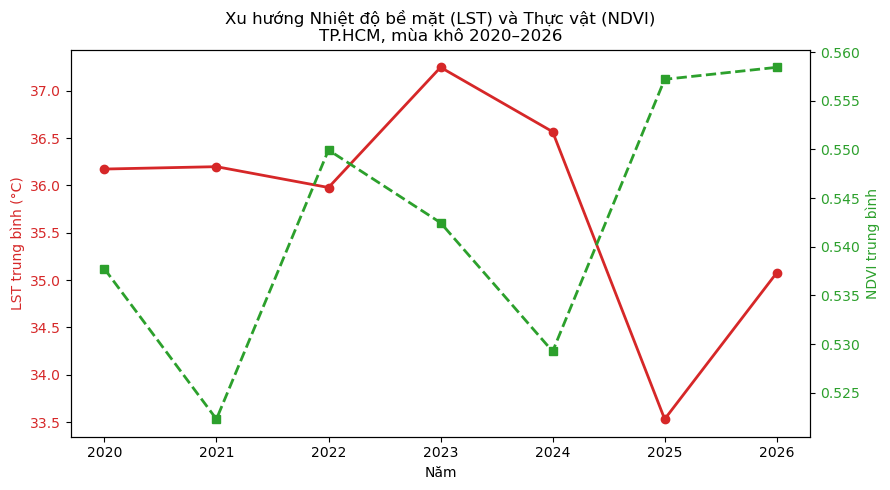

Tốc độ thay đổi LST trung bình: -0.287 °C/năm


In [7]:
fig, ax1 = plt.subplots(figsize=(9, 5))

color1 = 'tab:red'
ax1.set_xlabel('Năm')
ax1.set_ylabel('LST trung bình (°C)', color=color1)
ax1.plot(df.index, df['LST'], marker='o', color=color1, linewidth=2, label='LST')
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()
color2 = 'tab:green'
ax2.set_ylabel('NDVI trung bình', color=color2)
ax2.plot(df.index, df['NDVI'], marker='s', linestyle='--', color=color2, linewidth=2, label='NDVI')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Xu hướng Nhiệt độ bề mặt (LST) và Thực vật (NDVI)\nTP.HCM, mùa khô 2020–2026')
fig.tight_layout()
plt.savefig('trend_lst_ndvi.png', dpi=200)
plt.show()

# Tốc độ tăng nhiệt trung bình mỗi năm
slope = np.polyfit(df.index, df['LST'], 1)[0]
print(f'Tốc độ thay đổi LST trung bình: {slope:.3f} °C/năm')


## 7. Bản đồ LST tương tác từng năm (geemap)

In [8]:
lst_vis = {
    'min': 25, 'max': 45,
    'palette': ['040274', '2b83ba', 'abdda4', 'ffffbf', 'fdae61', 'd7191c', '780000']
}

Map2 = geemap.Map(center=[10.776, 106.700], zoom=10)
for y in YEARS:
    Map2.addLayer(yearly_images[y].select('LST'), lst_vis, f'LST {y}',  shown=(y == 2020) )

Map2.addLayer(aoi, {'color': 'black'}, 'Ranh giới TPHCM', opacity=0.4)
Map2.add_colorbar(lst_vis, label='LST (°C)')
Map2.centerObject(aoi, 10)
Map2


Map(center=[10.86837060102549, 106.84623864149141], controls=(WidgetControl(options=['position', 'transparent_…

### 7b. Xuất ảnh bản đồ từng năm cho WebGIS

Ảnh PNG nền trong suốt cho 5 lớp: LST (cùng thang màu `lst_vis` 25–45°C với bản đồ geemap ở trên), NDVI, NDBI, NDWI và UTFVI (6 mức theo ngưỡng mục 8). Ranh giới không vẽ vào ảnh — WebGIS vẽ chồng theo tọa độ. Kết quả: `maps/<lớp>_<năm>.png`.

In [ ]:
# 7b. Xuất ảnh bản đồ từng năm (PNG) cho WebGIS: LST, NDVI, NDBI, NDWI, UTFVI
# LST dùng CÙNG thang màu lst_vis ở trên (25–45°C). Ranh giới KHÔNG vẽ vào ảnh — web tự vẽ chồng theo tọa độ.
# Khung ảnh: phần đất liền của vùng nghiên cứu (không gồm Côn Đảo, cách bờ ~180 km).
import os, urllib.request

os.makedirs('maps', exist_ok=True)
khung_anh = ee.Geometry.Rectangle([106.30, 10.28, 107.62, 11.52])

map_vis = {
    'lst':  {'band': 'LST',  **lst_vis},
    'ndvi': {'band': 'NDVI', 'min': -0.2, 'max': 0.8, 'palette': ['8c510a', 'd8b365', 'f6e8c3', 'c7eae5', '7fbc41', '4d9221', '1b5e20']},
    'ndbi': {'band': 'NDBI', 'min': -0.5, 'max': 0.3, 'palette': ['2166ac', '67a9cf', 'd1e5f0', 'f7f7f7', 'fddbc7', 'ef8a62', 'b2182b']},
    'ndwi': {'band': 'NDWI', 'min': -0.7, 'max': 0.3, 'palette': ['a6611a', 'dfc27d', 'f5f5f5', 'c7eae5', '80cdc1', '35978f', '01665e']},
}
# UTFVI: phân 6 mức theo đúng ngưỡng mục 8 (0 / 0,005 / 0,010 / 0,015 / 0,020), mỗi năm so với LST TB của chính năm đó
utfvi_bins = [0, 0.005, 0.010, 0.015, 0.020]
utfvi_palette = ['0e9488', 'eab308', 'ea9c08', 'c77b12', 'c2410c', '9f1c2e']

for y in YEARS:
    img = yearly_images[y]
    for key, v in map_vis.items():
        anh = img.select(v['band']).visualize(min=v['min'], max=v['max'], palette=v['palette'])
        url = anh.getThumbURL({'region': khung_anh, 'dimensions': 1400, 'format': 'png', 'crs': 'EPSG:3857'})
        urllib.request.urlretrieve(url, f'maps/{key}_{y}.png')
    lst = img.select('LST')
    lst_tb = lst.reduceRegion(ee.Reducer.mean(), aoi_geom, 100, maxPixels=1e10, bestEffort=True).get('LST')
    u = lst.subtract(ee.Image.constant(lst_tb)).divide(ee.Image.constant(lst_tb))
    lop = ee.Image(0)
    for k, b in enumerate(utfvi_bins):
        lop = lop.where(u.gte(b), k + 1)
    anh = lop.updateMask(lst.mask()).visualize(min=0, max=5, palette=utfvi_palette)
    url = anh.getThumbURL({'region': khung_anh, 'dimensions': 1400, 'format': 'png', 'crs': 'EPSG:3857'})
    urllib.request.urlretrieve(url, f'maps/utfvi_{y}.png')
    print(f'Năm {y}: maps/{{lst,ndvi,ndbi,ndwi,utfvi}}_{y}.png', flush=True)

## 8. Phân vùng cường độ đảo nhiệt — Chỉ số UTFVI

**UTFVI (Urban Thermal Field Variance Index)** là chỉ số chuẩn để phân loại mức độ "đảo nhiệt" tương đối trong đô thị:

$$UTFVI = \frac{LST - LST_{mean}}{LST_{mean}}$$

Phân loại phổ biến (theo nhiều nghiên cứu UHI ở Việt Nam & châu Á):

| UTFVI | Mức độ đảo nhiệt |
|---|---|
| < 0 | Không có hiệu ứng UHI (mát) |
| 0 – 0.005 | Yếu |
| 0.005 – 0.010 | Trung bình |
| 0.010 – 0.015 | Mạnh |
| 0.015 – 0.020 | Rất mạnh |
| > 0.020 | Nghiêm trọng |


In [9]:
def calc_utfvi(image, aoi_geom):
    lst = image.select('LST')
    lst_mean = lst.reduceRegion(ee.Reducer.mean(), aoi_geom, 100, maxPixels=1e10, bestEffort=True).get('LST')
    lst_mean_img = ee.Image.constant(lst_mean)
    utfvi = lst.subtract(lst_mean_img).divide(lst_mean_img).rename('UTFVI')
    return utfvi

utfvi_2026 = calc_utfvi(yearly_images[2026], aoi_geom)

utfvi_vis = {
    'min': -0.02, 'max': 0.02,
    'palette': ['313695', '74add1', 'e0f3f8', 'fee090', 'fdae61', 'f46d43', 'a50026']
}

Map3 = geemap.Map(center=[10.776, 106.700], zoom=10)
Map3.addLayer(utfvi_2026, utfvi_vis, 'UTFVI 2026')
Map3.add_colorbar(utfvi_vis, label='UTFVI')
Map3.centerObject(aoi, 10)
Map3


Map(center=[10.86837060102549, 106.84623864149141], controls=(WidgetControl(options=['position', 'transparent_…

In [10]:
# Diện tích từng mức UTFVI (km2) - năm 2026 (ĐÃ SỬA LỖI)
bins = [-1, 0, 0.005, 0.010, 0.015, 0.020, 1]
labels = ['Không UHI', 'Yếu', 'Trung bình', 'Mạnh', 'Rất mạnh', 'Nghiêm trọng']

classified = ee.Image(0)
for i in range(len(labels)):
    mask = utfvi_2026.gte(bins[i]).And(utfvi_2026.lt(bins[i+1]))
    classified = classified.where(mask, i + 1)

area_img = ee.Image.pixelArea().divide(1e6).addBands(classified.rename('class'))  # km2
areas = area_img.reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='class'),
    geometry=aoi_geom, scale=100, maxPixels=1e10, bestEffort=True
).getInfo()

tong_chua_phan_loai = 0
utfvi_rows = []
for g in areas['groups']:
    class_id = int(g['class'])
    if class_id == 0:
        tong_chua_phan_loai = g['sum']
        continue
    idx = class_id - 1
    print(f"{labels[idx]:15s}: {g['sum']:.1f} km2")
    utfvi_rows.append({'year': 2026, 'order': idx, 'class_name': labels[idx], 'area_km2': round(g['sum'], 1)})

print(f"\n(Diện tích chưa phân loại được - biển/mây/ngoài vùng đất: {tong_chua_phan_loai:.1f} km2 - không tính vào các mức UHI)")

# Lưu ra CSV để WebGIS nạp thẳng (không phải chép tay số liệu)
pd.DataFrame(utfvi_rows).sort_values('order').to_csv('utfvi_2026.csv', index=False, encoding='utf-8-sig')
print('Đã lưu utfvi_2026.csv')

Không UHI      : 3328.1 km2
Yếu            : 116.1 km2
Trung bình     : 119.4 km2
Mạnh           : 113.2 km2
Rất mạnh       : 111.0 km2
Nghiêm trọng   : 2637.0 km2

(Diện tích chưa phân loại được - biển/mây/ngoài vùng đất: 223.9 km2 - không tính vào các mức UHI)
Đã lưu utfvi_2026.csv


### 8b. Diện tích từng mức UTFVI cho tất cả các năm 2020–2026

Cùng công thức, ngưỡng và độ phân giải với ô trên; mỗi năm dùng LST trung bình của chính năm đó. Kết quả: `utfvi_theo_nam.csv` (dùng cho WebGIS).

In [ ]:
# 8b. Diện tích từng mức UTFVI cho MỌI năm 2020–2026 — đúng cách của ô trên (calc_utfvi, cùng ngưỡng, scale 100 m)
# UTFVI mỗi năm dùng LST trung bình của CHÍNH năm đó.
bins = [-1, 0, 0.005, 0.010, 0.015, 0.020, 1]
labels = ['Không UHI', 'Yếu', 'Trung bình', 'Mạnh', 'Rất mạnh', 'Nghiêm trọng']

utfvi_all = []
for y in YEARS:
    u = calc_utfvi(yearly_images[y], aoi_geom)
    classified = ee.Image(0)
    for i in range(len(labels)):
        classified = classified.where(u.gte(bins[i]).And(u.lt(bins[i + 1])), i + 1)
    area_img = ee.Image.pixelArea().divide(1e6).addBands(classified.rename('class'))
    areas = area_img.reduceRegion(
        reducer=ee.Reducer.sum().group(groupField=1, groupName='class'),
        geometry=aoi_geom, scale=100, maxPixels=1e10, bestEffort=True, tileScale=4
    ).getInfo()
    chua_phan_loai = 0
    for g in areas['groups']:
        k = int(g['class'])
        if k == 0:
            chua_phan_loai = g['sum']
            continue
        utfvi_all.append({'year': y, 'order': k - 1, 'class_name': labels[k - 1], 'area_km2': round(g['sum'], 1)})
    # Phần không phân loại được (pixel bị che mây / không có dữ liệu trong AOI) — lưu lại để so sánh giữa các năm cho đúng
    utfvi_all.append({'year': y, 'order': 6, 'class_name': 'Không có dữ liệu', 'area_km2': round(chua_phan_loai, 1)})
    print(f'Năm {y}: ' + ' | '.join(f"{r['class_name']} {r['area_km2']}" for r in utfvi_all if r['year'] == y and r['order'] < 6)
          + f' | (chưa phân loại: {chua_phan_loai:.1f} km2)', flush=True)

pd.DataFrame(utfvi_all).sort_values(['year', 'order']).to_csv('utfvi_theo_nam.csv', index=False, encoding='utf-8-sig')
print('Đã lưu utfvi_theo_nam.csv')

## 9. Phân tích tương quan LST ~ NDVI ~ NDBI (lấy mẫu điểm ngẫu nhiên)

Hệ số tương quan Pearson  LST~NDVI: -0.291
Hệ số tương quan Pearson  LST~NDBI: 0.719


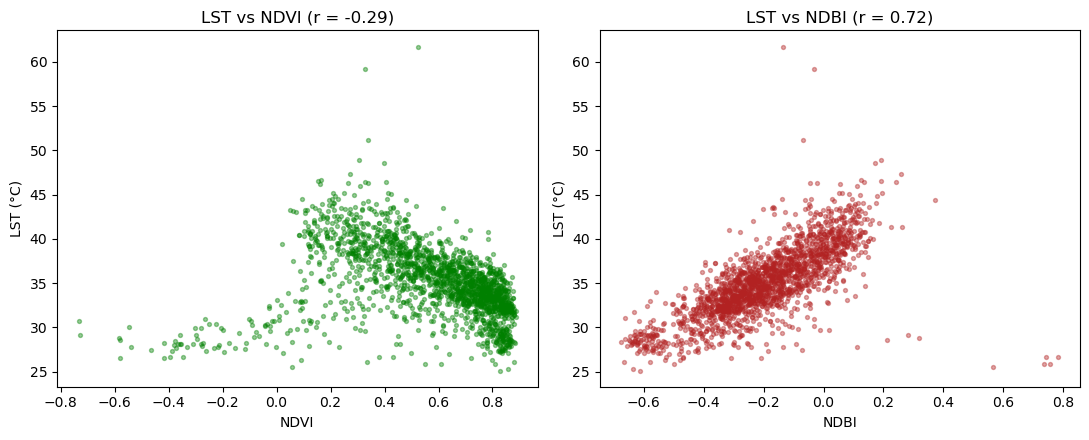

In [11]:
sample_points = yearly_images[2026].select(['LST', 'NDVI', 'NDBI']).sample(
    region=aoi_geom, scale=100, numPixels=2000, seed=42, geometries=False
)

sample_list = sample_points.getInfo()['features']
sample_df = pd.DataFrame([f['properties'] for f in sample_list]).dropna()

corr_ndvi = sample_df['LST'].corr(sample_df['NDVI'])
corr_ndbi = sample_df['LST'].corr(sample_df['NDBI'])
print(f'Hệ số tương quan Pearson  LST~NDVI: {corr_ndvi:.3f}')
print(f'Hệ số tương quan Pearson  LST~NDBI: {corr_ndbi:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(sample_df['NDVI'], sample_df['LST'], s=8, alpha=0.4, color='green')
axes[0].set_xlabel('NDVI'); axes[0].set_ylabel('LST (°C)')
axes[0].set_title(f'LST vs NDVI (r = {corr_ndvi:.2f})')

axes[1].scatter(sample_df['NDBI'], sample_df['LST'], s=8, alpha=0.4, color='firebrick')
axes[1].set_xlabel('NDBI'); axes[1].set_ylabel('LST (°C)')
axes[1].set_title(f'LST vs NDBI (r = {corr_ndbi:.2f})')

plt.tight_layout()
plt.savefig('correlation_lst.png', dpi=200)
plt.show()


**Diễn giải kỳ vọng:** LST thường **tương quan âm** với NDVI (nhiều cây xanh → mát hơn) và **tương quan dương** với NDBI (nhiều bê tông/công trình → nóng hơn). Đây là bằng chứng định lượng cho nguyên nhân đô thị hóa gây UHI — phần quan trọng cho mục "Đánh giá" trong tên đề tài.

### 9b. Xuất điểm mẫu pixel + hệ số tương quan theo từng năm (dùng cho WebGIS)

Mỗi năm lấy 2.000 điểm ngẫu nhiên (scale=100, seed=42 — cùng cách lấy mẫu như mục 9), giữ tọa độ
(`geometries=True`) để vẽ heatmap trên web. Từ chính các điểm này tính r(LST~NDBI), r(LST~NDVI).
Kết quả: `lst_points_<năm>.geojson` và `tuong_quan_theo_nam.csv`.

In [12]:
import json

corr_rows = []
all_points = []
for y in YEARS:
    fc = yearly_images[y].select(['LST', 'NDVI', 'NDBI', 'n_obs']).sample(
        region=aoi_geom, scale=100, numPixels=2000, seed=42, geometries=True
    )
    gj = fc.getInfo()
    feats = [f for f in gj['features']
             if all(f['properties'].get(k) is not None for k in ('LST', 'NDVI', 'NDBI'))]
    with open(f'lst_points_{y}.geojson', 'w', encoding='utf-8') as f:
        json.dump({'type': 'FeatureCollection', 'features': feats}, f, ensure_ascii=False)

    df_y = pd.DataFrame([f['properties'] for f in feats])
    corr_rows.append({'year': y,
                      'r_ndbi': round(df_y['LST'].corr(df_y['NDBI']), 3),
                      'r_ndvi': round(df_y['LST'].corr(df_y['NDVI']), 3),
                      'n_points': len(df_y)})
    for f in feats:
        lon, lat = f['geometry']['coordinates'][:2]
        all_points.append({'year': y, 'lat': lat, 'lon': lon, **f['properties']})
    print(f'Năm {y}: {len(feats)} điểm -> lst_points_{y}.geojson')

corr_df = pd.DataFrame(corr_rows)
corr_df.to_csv('tuong_quan_theo_nam.csv', index=False)
print(corr_df)

Năm 2020: 1862 điểm -> lst_points_2020.geojson
Năm 2021: 1922 điểm -> lst_points_2021.geojson
Năm 2022: 1824 điểm -> lst_points_2022.geojson
Năm 2023: 1909 điểm -> lst_points_2023.geojson
Năm 2024: 1923 điểm -> lst_points_2024.geojson
Năm 2025: 1839 điểm -> lst_points_2025.geojson
Năm 2026: 1910 điểm -> lst_points_2026.geojson
   year  r_ndbi  r_ndvi  n_points
0  2020   0.790  -0.345      1862
1  2021   0.690  -0.214      1922
2  2022   0.699  -0.283      1824
3  2023   0.746  -0.271      1909
4  2024   0.716  -0.300      1923
5  2025   0.647  -0.306      1839
6  2026   0.719  -0.291      1910


### 9c. Kiểm tra điểm nóng bất thường sau khi che mây chặt hơn

Trước khi sửa che mây có 4 điểm LST ≥ 58°C nằm trên vườn cây/rừng (NDVI ≈ 0,3–0,5) — không hợp lý
vật lý. Ô dưới in 10 điểm nóng nhất mỗi năm kèm `n_obs` (số ảnh hợp lệ tại pixel) và kiểm tra lại
đúng vị trí điểm 67°C cũ.

In [13]:
pts_df = pd.DataFrame(all_points)
print('Số điểm LST ≥ 50°C theo năm:')
print(pts_df[pts_df['LST'] >= 50].groupby('year').size().reindex(YEARS, fill_value=0))
print('\n10 điểm nóng nhất (mọi năm):')
print(pts_df.sort_values('LST', ascending=False).head(10)[['year', 'lat', 'lon', 'LST', 'NDVI', 'NDBI', 'n_obs']])

# Vị trí điểm 67°C trong lần chạy cũ (Châu Đức, vườn cây)
pt_cu = ee.Geometry.Point([107.25502, 10.62814])
v = yearly_images[2026].select(['LST', 'NDVI', 'n_obs']).reduceRegion(ee.Reducer.first(), pt_cu, 100).getInfo()
print('\nTại vị trí điểm 67°C cũ, năm 2026 sau khi sửa:', v)

Số điểm LST ≥ 50°C theo năm:
year
2020     7
2021     3
2022     9
2023    11
2024     6
2025     2
2026     3
dtype: int64

10 điểm nóng nhất (mọi năm):
       year        lat         lon        LST      NDVI      NDBI  n_obs
8157   2024  10.458805  107.065442  67.905126  0.474306 -0.068007      5
6243   2023  10.458805  107.065442  66.989096  0.404034 -0.039148      3
2500   2021  10.458805  107.065442  66.965170  0.471789 -0.048541      4
623    2020  10.458805  107.065442  66.896810  0.406894 -0.107046      2
10049  2025  10.458805  107.065442  65.915838  0.487218 -0.077375      1
4399   2022  10.458805  107.065442  65.064751  0.455351 -0.044115      3
6419   2023  10.823262  106.764249  63.195094  0.272134 -0.048987      1
2676   2021  10.823262  106.764249  62.135508  0.315554 -0.094353      3
11910  2026  10.458805  107.065442  61.728764  0.525420 -0.135398      1
8332   2024  10.823262  106.764249  61.662112  0.272218 -0.035638      6

Tại vị trí điểm 67°C cũ, năm 2026 sau khi 

### 9d. Lưới ô 1 km + thống kê theo quận/huyện (cho trang Bản đồ của WebGIS)

Mỗi ô 1 km là trung bình các pixel 30 m hợp lệ bên trong ô (`reduceResolution`, không nội suy); `coverage` = tỉ lệ diện tích ô có dữ liệu sau che mây. Quận/huyện theo FAO GAUL 2015 cấp 2 (cùng bộ dữ liệu với AOI — ranh giới năm 2015, một số đơn vị đã thay đổi). Kết quả: `lst_grid_1km_<năm>.geojson`, `ranh_gioi_quan_huyen_gaul2015.geojson`, `thong_ke_quan_huyen.csv`.

In [ ]:
# 9d. Lưới ô 1 km + thống kê theo quận/huyện — dữ liệu cho trang Bản đồ của WebGIS
# Mỗi ô 1 km = TRUNG BÌNH các pixel 30 m hợp lệ bên trong ô (reduceResolution, không nội suy).
# coverage = tỉ lệ diện tích ô có pixel LST hợp lệ (0–1) sau che mây.
import json

GRID_SCALE = 1000
proj_utm = ee.Projection('EPSG:32648')
grid_bands = ['LST', 'NDVI', 'NDBI', 'NDWI']

def grid_image(y):
    img = yearly_images[y].select(grid_bands)
    coverage = img.select('LST').mask().unmask(0).rename('coverage')
    return (img.addBands(coverage)
            .setDefaultProjection(proj_utm.atScale(30))
            .reduceResolution(ee.Reducer.mean(), maxPixels=1200)
            .reproject(proj_utm.atScale(GRID_SCALE)))

def sample_cells(g, geom, label, depth=0):
    """Lấy ô lưới trong geom; nếu Earth Engine báo tràn bộ nhớ thì chia vùng thành 4 phần và lấy lại."""
    try:
        fc = g.sample(region=geom, scale=GRID_SCALE, projection=proj_utm, geometries=True, tileScale=8).getInfo()
        print(f'  {label}: {len(fc["features"])} ô', flush=True)
        return fc['features']
    except ee.EEException as e:
        if 'memory' not in str(e).lower() or depth >= 3:
            raise
        coords = ee.List(geom.bounds().coordinates().get(0)).getInfo()
        xs, ys = [p[0] for p in coords], [p[1] for p in coords]
        x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
        xm, ym = (x0 + x1) / 2, (y0 + y1) / 2
        out = []
        for k, (a, b, c_, d) in enumerate([(x0, y0, xm, ym), (xm, y0, x1, ym), (x0, ym, xm, y1), (xm, ym, x1, y1)]):
            part = geom.intersection(ee.Geometry.Rectangle([a, b, c_, d]), maxError=1)
            out += sample_cells(g, part, f'{label} / phần {k + 1}', depth + 1)
        return out

for y in YEARS:
    g = grid_image(y)
    seen, feats = set(), []
    # Lấy theo từng tỉnh cũ (mỗi lần getInfo < 5.000 đối tượng); tự chia nhỏ nếu tràn bộ nhớ
    for ten in ten_3_tinh:
        region = aoi.filter(ee.Filter.eq('ADM1_NAME', ten)).geometry()
        for f in sample_cells(g, region, f'{y} · {ten}'):
            lon, lat = f['geometry']['coordinates'][:2]
            key = (round(lon, 5), round(lat, 5))
            if key in seen or f['properties'].get('LST') is None:
                continue
            seen.add(key)
            feats.append({'type': 'Feature', 'geometry': {'type': 'Point', 'coordinates': [lon, lat]},
                          'properties': {k: f['properties'].get(k) for k in grid_bands + ['coverage']}})
    with open(f'lst_grid_1km_{y}.geojson', 'w', encoding='utf-8') as fo:
        json.dump({'type': 'FeatureCollection', 'cell_m': GRID_SCALE, 'features': feats}, fo, ensure_ascii=False)
    print(f'Năm {y}: {len(feats)} ô 1 km -> lst_grid_1km_{y}.geojson', flush=True)

# Quận/huyện: ranh giới FAO GAUL 2015 cấp 2 (cùng bộ dữ liệu với AOI) — trung bình toàn bộ pixel 100 m
districts = ee.FeatureCollection('FAO/GAUL/2015/level2').filter(ee.Filter.inList('ADM1_NAME', ten_3_tinh))
gj = districts.map(lambda f: ee.Feature(f.geometry().simplify(maxError=30),
                                        {'ADM2_CODE': f.get('ADM2_CODE'), 'ADM2_NAME': f.get('ADM2_NAME'),
                                         'ADM1_NAME': f.get('ADM1_NAME')})).getInfo()
with open('ranh_gioi_quan_huyen_gaul2015.geojson', 'w', encoding='utf-8') as fo:
    json.dump(gj, fo, ensure_ascii=False)

district_rows = []
for y in YEARS:
    feats_y = []
    for ten in ten_3_tinh:   # theo từng tỉnh để giảm bộ nhớ mỗi lần tính
        stats = yearly_images[y].select(grid_bands).reduceRegions(
            collection=districts.filter(ee.Filter.eq('ADM1_NAME', ten)),
            reducer=ee.Reducer.mean(), scale=100, tileScale=8).getInfo()
        feats_y += stats['features']
    print(f'  Thống kê quận/huyện {y}: {len(feats_y)} đơn vị', flush=True)
    for f in feats_y:
        p = f['properties']
        district_rows.append({'year': y, 'ADM2_CODE': p['ADM2_CODE'], 'ADM2_NAME': p['ADM2_NAME'],
                              'ADM1_NAME': p['ADM1_NAME'], **{b: p.get(b) for b in grid_bands}})
district_df = pd.DataFrame(district_rows)
district_df.to_csv('thong_ke_quan_huyen.csv', index=False, encoding='utf-8-sig')
print(f'{len(gj["features"])} quận/huyện -> ranh_gioi_quan_huyen_gaul2015.geojson, thong_ke_quan_huyen.csv')
print(district_df[district_df['year'] == YEARS[-1]].sort_values('LST', ascending=False).head(10)[['ADM2_NAME', 'LST', 'NDVI', 'NDBI']])

## 10. Xuất raster ra Google Drive (phục vụ làm bản đồ trong QGIS/ArcGIS nếu cần)

Mỗi lệnh `Export.image.toDrive` sẽ đưa một tiến trình vào hàng đợi (Task) của GEE, chạy ngầm trên server Google — không chiếm tài nguyên Colab. Theo dõi tiến trình tại tab **Tasks** trên [Earth Engine Code Editor](https://code.earthengine.google.com/tasks).


In [14]:
export_bands = ['LST', 'NDVI', 'NDBI', 'NDWI']

for y in YEARS:
    task = ee.batch.Export.image.toDrive(
        image=yearly_images[y].select(export_bands),
        description=f'TPHCM_UHI_{y}',
        folder='UHI_TPHCM_DoAn',
        fileNamePrefix=f'TPHCM_LST_indices_{y}',
        region=aoi_geom,
        scale=30,
        crs='EPSG:32648',   # UTM Zone 48N, phù hợp cho TPHCM
        maxPixels=1e10
    )
    task.start()
    print(f'-> Đã đưa tiến trình xuất TPHCM_LST_indices_{y} vào hàng đợi GEE.')


-> Đã đưa tiến trình xuất TPHCM_LST_indices_2020 vào hàng đợi GEE.
-> Đã đưa tiến trình xuất TPHCM_LST_indices_2021 vào hàng đợi GEE.
-> Đã đưa tiến trình xuất TPHCM_LST_indices_2022 vào hàng đợi GEE.
-> Đã đưa tiến trình xuất TPHCM_LST_indices_2023 vào hàng đợi GEE.
-> Đã đưa tiến trình xuất TPHCM_LST_indices_2024 vào hàng đợi GEE.
-> Đã đưa tiến trình xuất TPHCM_LST_indices_2025 vào hàng đợi GEE.
-> Đã đưa tiến trình xuất TPHCM_LST_indices_2026 vào hàng đợi GEE.


## 11. MÔ PHỎNG (A) — Dự báo xu hướng LST 2027–2030 bằng hồi quy

Đây là phần **mô phỏng đơn giản** dùng chuỗi số liệu LST trung bình 2020–2026 đã trích xuất ở Bước 5, để ngoại suy xu hướng nhiệt độ những năm tới. Dùng cả hồi quy tuyến tính và đa thức bậc 2 để so sánh, tránh chỉ dựa vào 1 mô hình.


In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

X = df.index.values.reshape(-1, 1).astype(float)
y_lst = df['LST'].values

# Mô hình tuyến tính
lin_model = LinearRegression().fit(X, y_lst)
r2_lin = r2_score(y_lst, lin_model.predict(X))

# Mô hình đa thức bậc 2
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
poly_model = LinearRegression().fit(X_poly, y_lst)
r2_poly = r2_score(y_lst, poly_model.predict(X_poly))

future_years = np.array([2027, 2028, 2029, 2030]).reshape(-1, 1).astype(float)
pred_lin = lin_model.predict(future_years)
pred_poly = poly_model.predict(poly.transform(future_years))

forecast_df = pd.DataFrame({
    'year': future_years.flatten().astype(int),
    'LST_du_bao_tuyen_tinh': pred_lin,
    'LST_du_bao_da_thuc': pred_poly
}).set_index('year')

print(f'R2 mô hình tuyến tính: {r2_lin:.3f}')
print(f'R2 mô hình đa thức bậc 2: {r2_poly:.3f}')
forecast_df


R2 mô hình tuyến tính: 0.265
R2 mô hình đa thức bậc 2: 0.413


,LST_du_bao_tuyen_tinh,LST_du_bao_da_thuc
year,,
2027,34.677069,33.194628
2028,34.390150,31.795878
2029,34.103231,30.150055
2030,33.816312,28.257158


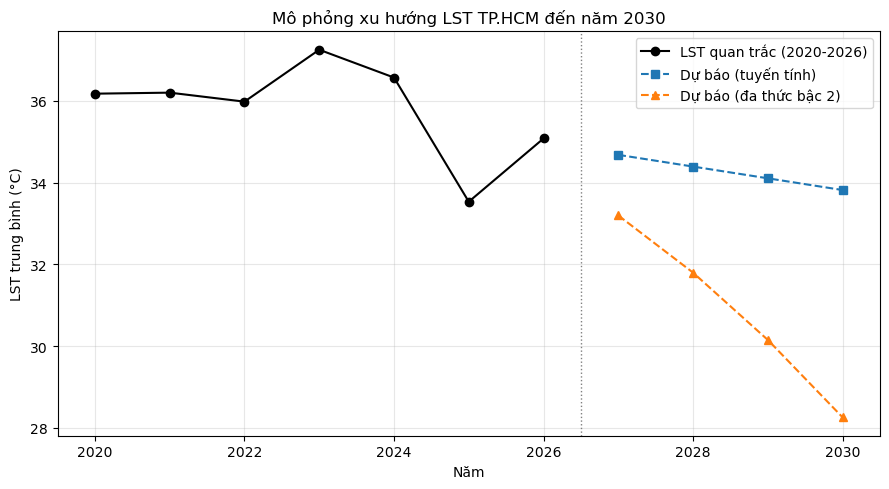

In [16]:
plt.figure(figsize=(9, 5))
plt.plot(df.index, df['LST'], 'o-', color='black', label='LST quan trắc (2020-2026)')
plt.plot(forecast_df.index, forecast_df['LST_du_bao_tuyen_tinh'], 's--', color='tab:blue', label='Dự báo (tuyến tính)')
plt.plot(forecast_df.index, forecast_df['LST_du_bao_da_thuc'], '^--', color='tab:orange', label='Dự báo (đa thức bậc 2)')
plt.axvline(2026.5, color='gray', linestyle=':', linewidth=1)
plt.xlabel('Năm'); plt.ylabel('LST trung bình (°C)')
plt.title('Mô phỏng xu hướng LST TP.HCM đến năm 2030')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('forecast_lst.png', dpi=200)
plt.show()


### 11b. Xuất kết quả dự báo + kiểm định 2026 (cho WebGIS)

Kiểm định ngược: huấn luyện cùng 2 mô hình trên 2020–2025, dự báo 2026 rồi so với LST 2026 quan trắc thật. Kết quả: `du_bao_lst.csv`, `kiem_dinh_2026.csv`.

In [ ]:
# 11b. Xuất kết quả dự báo + kiểm định 2026 (dùng cho WebGIS)
# Kiểm định: huấn luyện CÙNG 2 mô hình trên 2020–2025, dự báo 2026 rồi so với LST 2026 quan trắc thật.
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

forecast_df.reset_index().rename(columns={
    'LST_du_bao_tuyen_tinh': 'lst_linear', 'LST_du_bao_da_thuc': 'lst_poly'
}).assign(r2_linear=round(r2_lin, 4), r2_poly=round(r2_poly, 4)).to_csv('du_bao_lst.csv', index=False)

train = df.loc[df.index < 2026]
X_tr = train.index.values.reshape(-1, 1).astype(float)
X_26 = np.array([[2026.0]])
bt_lin = LinearRegression().fit(X_tr, train['LST'].values)
poly_bt = PolynomialFeatures(degree=2)
bt_poly = LinearRegression().fit(poly_bt.fit_transform(X_tr), train['LST'].values)
actual_2026 = float(df.loc[2026, 'LST'])
kiem_dinh = pd.DataFrame([
    {'model': 'tuyen_tinh', 'train_years': '2020-2025', 'pred_2026': float(bt_lin.predict(X_26)[0]), 'actual_2026': actual_2026},
    {'model': 'da_thuc_bac_2', 'train_years': '2020-2025', 'pred_2026': float(bt_poly.predict(poly_bt.transform(X_26))[0]), 'actual_2026': actual_2026},
])
kiem_dinh['error'] = kiem_dinh['pred_2026'] - kiem_dinh['actual_2026']
kiem_dinh.to_csv('kiem_dinh_2026.csv', index=False)
print(kiem_dinh)

### 11c. Dự báo cho mọi chỉ số và từng quận/huyện (cho WebGIS)

Cùng 2 mô hình của mục 11, áp dụng cho LST, NDVI, NDBI, NDWI của toàn vùng và 38 quận/huyện; kèm kiểm định ngược 2026. Mỗi chuỗi chỉ có 7 năm nên dự báo cấp quận/huyện kém tin cậy hơn toàn vùng. Kết quả: `du_bao_theo_chi_so.csv`.

In [ ]:
# 11c. Dự báo 2027–2030 + kiểm định 2026 cho MỌI chỉ số (LST, NDVI, NDBI, NDWI)
#      và cho toàn vùng + từng quận/huyện — CÙNG 2 mô hình của mục 11 (tuyến tính, đa thức bậc 2)
# Dữ liệu vào: df (trung bình toàn vùng, mục 5) và district_df (trung bình quận/huyện, mục 9d).
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

def du_bao_chuoi(nam, gia_tri, nam_tuong_lai=(2027, 2028, 2029, 2030)):
    X = np.array(nam, dtype=float).reshape(-1, 1); y = np.array(gia_tri, dtype=float)
    poly = PolynomialFeatures(degree=2)
    lin = LinearRegression().fit(X, y)
    pol = LinearRegression().fit(poly.fit_transform(X), y)
    Xf = np.array(nam_tuong_lai, dtype=float).reshape(-1, 1)
    # Kiểm định ngược: huấn luyện trên các năm < 2026, dự báo 2026, so với quan trắc
    m = X[:, 0] < 2026
    bt_lin = LinearRegression().fit(X[m], y[m]).predict([[2026.0]])[0]
    poly_bt = PolynomialFeatures(degree=2)
    bt_pol = LinearRegression().fit(poly_bt.fit_transform(X[m]), y[m]).predict(poly_bt.transform([[2026.0]]))[0]
    return {
        'lin': lin.predict(Xf), 'pol': pol.predict(poly.transform(Xf)),
        'r2_lin': r2_score(y, lin.predict(X)), 'r2_pol': r2_score(y, pol.predict(poly.transform(X))),
        'bt_lin': bt_lin, 'bt_pol': bt_pol, 'actual_2026': float(y[~m][0]) if (~m).any() else np.nan,
    }

chi_so = ['LST', 'NDVI', 'NDBI', 'NDWI']
pham_vi = [('all', 'Toàn vùng', df.reset_index().rename(columns={'index': 'year'}))]
for (code, name), g in district_df.groupby(['ADM2_CODE', 'ADM2_NAME']):
    pham_vi.append((f'gaul:{int(code)}', name, g))

dong = []
for scope, ten, g in pham_vi:
    g = g.sort_values('year')
    for cs in chi_so:
        s = g[['year', cs]].dropna()
        if len(s) < 4:
            continue
        kq = du_bao_chuoi(s['year'].values, s[cs].values)
        for k, nam in enumerate((2027, 2028, 2029, 2030)):
            dong.append({'scope': scope, 'scope_name': ten, 'index': cs.lower(), 'year': nam,
                         'linear': kq['lin'][k], 'poly': kq['pol'][k],
                         'r2_linear': kq['r2_lin'], 'r2_poly': kq['r2_pol'],
                         'bt_pred_linear': kq['bt_lin'], 'bt_pred_poly': kq['bt_pol'], 'actual_2026': kq['actual_2026']})

du_bao_df = pd.DataFrame(dong)
du_bao_df.to_csv('du_bao_theo_chi_so.csv', index=False, encoding='utf-8-sig')
print(f"{du_bao_df[['scope', 'index']].drop_duplicates().shape[0]} chuỗi dự báo -> du_bao_theo_chi_so.csv")
print(du_bao_df[du_bao_df['scope'] == 'all'].query('year == 2030')[['index', 'linear', 'poly', 'r2_linear', 'bt_pred_linear', 'actual_2026']])

> **Lưu ý học thuật:** với chuỗi số liệu ngắn (7 điểm dữ liệu), mô hình đa thức bậc cao dễ **overfitting** — nên ưu tiên trình bày mô hình tuyến tính là chính, mô hình đa thức chỉ để tham khảo/so sánh, và luôn nêu rõ giới hạn của phương pháp ngoại suy tuyến tính trong phần Kết luận.

## 12. MÔ PHỎNG (B) — Dự báo mở rộng đô thị bằng Cellular Automata – Markov (đơn giản hóa)

Đây là phần nâng cao, mô phỏng **không gian** thay vì chỉ 1 con số trung bình như trên. Ý tưởng:

1. Lấy 2 lớp phủ đất (LULC) tại 2 thời điểm (2020 và 2026) từ ảnh phân loại có sẵn (ESA WorldCover hoặc Dynamic World trên GEE).
2. Tính **ma trận chuyển đổi Markov**: xác suất 1 pixel đất trống/nông nghiệp chuyển thành đất xây dựng.
3. Dùng ma trận này + luật lân cận (Cellular Automata) để mô phỏng bản đồ LULC năm 2030.
4. Từ bản đồ LULC mô phỏng, suy ra LST tương lai dựa trên mối quan hệ NDBI~LST đã tìm được ở Bước 9.


In [17]:
# --- 12.1: Lấy lớp phủ đất từ ESA WorldCover (2020 và 2021 - phiên bản mới nhất hiện có public)
worldcover_2020 = ee.Image('ESA/WorldCover/v100/2020').select('Map').clip(aoi_geom)
worldcover_2021 = ee.Image('ESA/WorldCover/v200/2021').select('Map').clip(aoi_geom)

# Gộp lớp: 1 = Đất xây dựng (Built-up, mã 50), 0 = Lớp phủ khác
builtup_2020 = worldcover_2020.eq(50).rename('builtup')
builtup_2021 = worldcover_2021.eq(50).rename('builtup')

# Xuất mẫu điểm ngẫu nhiên để tính ma trận chuyển đổi bằng numpy (nhẹ hơn xử lý full raster)
sample_lulc = builtup_2020.addBands(builtup_2021).sample(
    region=aoi_geom, scale=30, numPixels=5000, seed=1, geometries=False
).getInfo()['features']

lulc_df = pd.DataFrame([f['properties'] for f in sample_lulc]).dropna()
lulc_df.columns = ['builtup_2020', 'builtup_2021']
lulc_df = lulc_df.astype(int)
lulc_df.head()


,builtup_2020,builtup_2021
0,0,0
1,0,0
2,0,1
3,0,0
4,1,1


In [18]:
# --- 12.2: Ma trận chuyển đổi Markov (xác suất chuyển trạng thái)
from collections import Counter

trans_counts = Counter(zip(lulc_df['builtup_2020'], lulc_df['builtup_2021']))
total_from_0 = sum(v for k, v in trans_counts.items() if k[0] == 0)
total_from_1 = sum(v for k, v in trans_counts.items() if k[0] == 1)

p_00 = trans_counts.get((0, 0), 0) / total_from_0   # giữ nguyên đất trống
p_01 = trans_counts.get((0, 1), 0) / total_from_0   # đất trống -> đô thị hóa
p_10 = trans_counts.get((1, 0), 0) / total_from_1   # đô thị -> đất trống (hiếm)
p_11 = trans_counts.get((1, 1), 0) / total_from_1   # giữ nguyên đô thị

transition_matrix = pd.DataFrame(
    [[p_00, p_01], [p_10, p_11]],
    index=['Từ: Đất khác', 'Từ: Đô thị'],
    columns=['Đến: Đất khác', 'Đến: Đô thị']
)
print('Ma trận chuyển đổi Markov (1 chu kỳ ~ 1 năm, 2020->2021):')
transition_matrix.round(4)


Ma trận chuyển đổi Markov (1 chu kỳ ~ 1 năm, 2020->2021):


,Đến: Đất khác,Đến: Đô thị
Từ: Đất khác,0.9816,0.0184
Từ: Đô thị,0.0613,0.9387


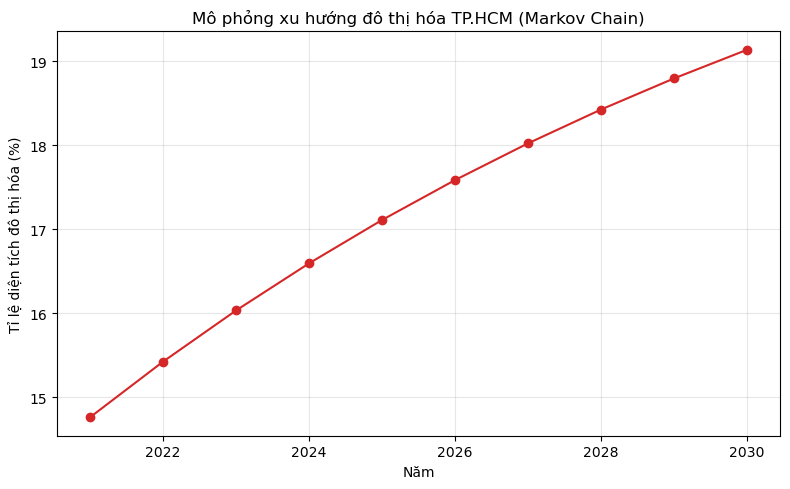

Tỉ lệ đô thị hóa dự báo năm 2030: 19.1%


In [19]:
# --- 12.3: Ngoại suy tỉ lệ đô thị hóa đến năm 2030 bằng chuỗi Markov
n_years_forecast = 2030 - 2021  # số bước lặp từ 2021 -> 2030
T = np.array([[p_00, p_01],
              [p_10, p_11]])

# Trạng thái ban đầu: [tỉ lệ đất khác, tỉ lệ đô thị] năm 2021
state = np.array([1 - lulc_df['builtup_2021'].mean(), lulc_df['builtup_2021'].mean()])

history = [state]
for _ in range(n_years_forecast):
    state = state @ T
    history.append(state)

markov_forecast = pd.DataFrame(history, columns=['Ti_le_dat_khac', 'Ti_le_do_thi'])
markov_forecast['year'] = range(2021, 2031)
markov_forecast = markov_forecast.set_index('year')

plt.figure(figsize=(8, 5))
plt.plot(markov_forecast.index, markov_forecast['Ti_le_do_thi'] * 100, marker='o', color='tab:red')
plt.xlabel('Năm'); plt.ylabel('Tỉ lệ diện tích đô thị hóa (%)')
plt.title('Mô phỏng xu hướng đô thị hóa TP.HCM (Markov Chain)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('markov_urbanization.png', dpi=200)
plt.show()

print(f"Tỉ lệ đô thị hóa dự báo năm 2030: {markov_forecast.loc[2030, 'Ti_le_do_thi']*100:.1f}%")


> **Ghi chú phương pháp luận (nên đưa vào báo cáo):**
> - Đây là mô hình Markov Chain **bậc 1, đồng nhất không gian** (không phân biệt vị trí pixel) — phiên bản CA-Markov đầy đủ cần thêm **luật lân cận không gian** (spatial neighborhood rules, ví dụ dùng `scipy.ndimage` hoặc thư viện `pylandstats`/`clumpy`) để mô phỏng ra *bản đồ* LULC 2030 thay vì chỉ tỉ lệ %.
> - Với đồ án môn học, việc trình bày tỉ lệ đô thị hóa dự báo + liên hệ với tương quan NDBI~LST (mục 9) để **suy luận định tính** xu hướng UHI 2030 là đã đủ chiều sâu.
> - Nếu muốn làm CA-Markov không gian đầy đủ, có thể dùng bổ sung phần mở rộng bên dưới (tùy chọn, không bắt buộc).


In [20]:
# ==== PHẦN MỞ RỘNG (TÙY CHỌN): CA-Markov có luật lân cận không gian ====
# Ý tưởng: pixel đất trống có xác suất chuyển thành đô thị TĂNG nếu xung quanh
# đã có nhiều pixel đô thị (hiệu ứng lan toả đô thị hóa - urban sprawl).
#
# Yêu cầu: tải raster builtup_2021 dạng numpy array (qua geemap.ee_to_numpy hoặc
# export ảnh nhỏ về rồi đọc bằng rasterio), sau đó áp dụng vòng lặp:
#
# from scipy.ndimage import uniform_filter
# for step in range(n_years_forecast):
#     neighbor_density = uniform_filter(builtup_array.astype(float), size=3)
#     transition_prob = p_01 * (1 + neighbor_density)   # tăng xác suất theo mật độ lân cận
#     transition_prob = np.clip(transition_prob, 0, 1)
#     random_field = np.random.rand(*builtup_array.shape)
#     new_builtup = np.where((builtup_array == 0) & (random_field < transition_prob), 1, builtup_array)
#     builtup_array = new_builtup
#
# Phần này đòi hỏi làm việc với raster thực (numpy array), khác với sample điểm
# đang dùng ở trên -> nếu triển khai, em nên export builtup_2021 ra Drive/local
# trước rồi đọc bằng rasterio.open().read(1) để có đúng ma trận 2 chiều.
print('Đây là khung code tham khảo cho phần mở rộng CA không gian - không chạy trực tiếp.')


Đây là khung code tham khảo cho phần mở rộng CA không gian - không chạy trực tiếp.


## 13. Tổng hợp kết quả & Gợi ý viết báo cáo

### Bảng tổng hợp số liệu chính (đưa vào phần "Kết quả" của báo cáo)


In [21]:
summary = df.copy()
summary['UTFVI_slope_ghi_chu'] = 'Xem Bước 8 để lấy diện tích từng mức UHI'
summary.to_csv('bang_tong_hop_UHI_TPHCM_2020_2026.csv', encoding='utf-8-sig')
summary


,LST,NDBI,NDVI,NDWI,UTFVI_slope_ghi_chu
year,,,,,
2020,36.173207,-0.175046,0.537739,-0.512074,Xem Bước 8 để lấy diện tích từng mức UHI
2021,36.198319,-0.156641,0.522295,-0.496807,Xem Bước 8 để lấy diện tích từng mức UHI
2022,35.978157,-0.187640,0.549936,-0.516521,Xem Bước 8 để lấy diện tích từng mức UHI
2023,37.248026,-0.178828,0.542469,-0.505697,Xem Bước 8 để lấy diện tích từng mức UHI
2024,36.567525,-0.173711,0.529252,-0.504256,Xem Bước 8 để lấy diện tích từng mức UHI
2025,33.530772,-0.190879,0.557200,-0.522354,Xem Bước 8 để lấy diện tích từng mức UHI
2026,35.077206,-0.184859,0.558433,-0.510524,Xem Bước 8 để lấy diện tích từng mức UHI


### Gợi ý cấu trúc trình bày trong báo cáo (Word/PowerPoint)

| Mục | Nội dung lấy từ notebook |
|---|---|
| 4.1 Bản đồ LST theo năm | Ảnh chụp màn hình từ Bước 7 (geemap), hoặc mở file .tif đã export (Bước 10) trong QGIS để trình bày đẹp hơn |
| 4.2 Xu hướng UHI theo thời gian | Biểu đồ Bước 6 (`trend_lst_ndvi.png`) |
| 4.3 Tương quan LST ~ LULC/NDVI | Biểu đồ Bước 9 (`correlation_lst.png`) + hệ số r |
| 4.4 Phân vùng cường độ UHI | Bản đồ UTFVI Bước 8 + bảng diện tích từng mức |
| 4.5 Kịch bản mô phỏng tương lai | Biểu đồ dự báo Bước 11 (`forecast_lst.png`) + Bước 12 (`markov_urbanization.png`) |
| 5. Kết luận | Tổng hợp: LST tăng bao nhiêu °C/năm, vùng nào UHI nghiêm trọng nhất (thường là Q1, Q3, Q5, Bình Thạnh, Tân Bình — khu lõi đô thị cũ mật độ cao), khuyến nghị (tăng mảng xanh, mặt nước, vật liệu phản xạ nhiệt...) |

### Các file kết quả đã tạo ra trong notebook này:
- `trend_lst_ndvi.png` — biểu đồ xu hướng LST/NDVI
- `correlation_lst.png` — biểu đồ tương quan
- `forecast_lst.png` — dự báo LST 2027-2030
- `markov_urbanization.png` — dự báo đô thị hóa
- `bang_tong_hop_UHI_TPHCM_2020_2026.csv` — bảng số liệu
- Các file `.tif` trên Google Drive (thư mục `UHI_TPHCM_DoAn`) — dùng cho GIS
